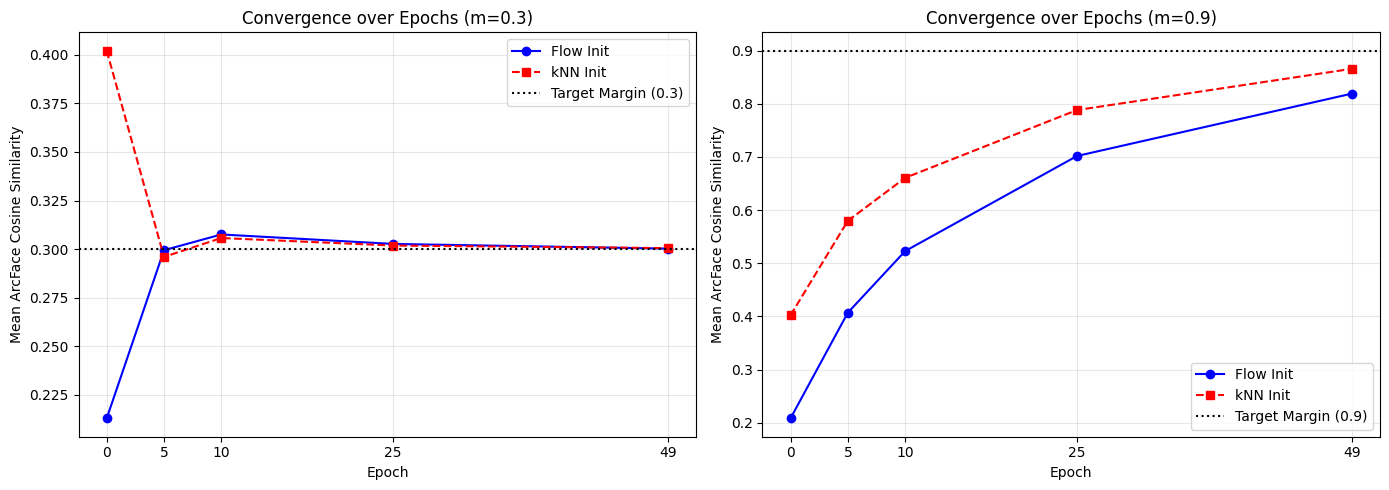

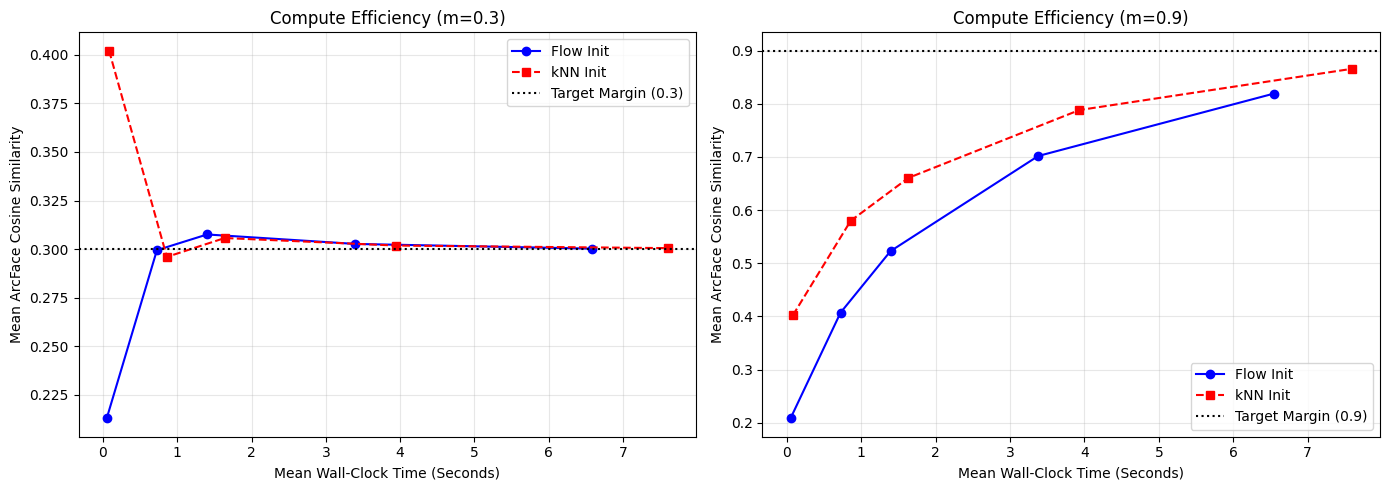

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path("/home/s142301038-unnikrishnan/tard/FALCO")#.resolve().parents[2]

def load_and_average(csv_path):
    """Loads CSV and averages the metrics across all images for each epoch."""
    try:
        df = pd.read_csv(csv_path)
        # Group by epoch and calculate the mean for all numerical columns
        return df.groupby('epoch').mean().reset_index()
    except FileNotFoundError:
        print(f"Warning: {csv_path} not found. Returning empty dataframe.")
        return pd.DataFrame(columns=['epoch', 'arcface_cos', 'id_loss', 'att_loss', 'wall_clock_time'])

# 1. Load data
flow_m03 = load_and_average(ROOT / "endterm" / "logs" / "m_0.3" / "convergence_log_flow.csv")
knn_m03  = load_and_average(ROOT / "logs" / "m_0.3" / "convergence_log_knn.csv")
flow_m09 = load_and_average(ROOT / "endterm" / "logs" / "m_0.9" / "convergence_log_flow.csv")
knn_m09  = load_and_average(ROOT / "logs" / "m_0.9" / "convergence_log_knn.csv")

# ==========================================
# PLOT 1: ArcFace Cosine Similarity vs. Epochs
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot A: m = 0.3
if not flow_m03.empty and not knn_m03.empty:
    ax1.plot(flow_m03['epoch'], flow_m03['arcface_cos'], marker='o', linestyle='-', color='blue', label='Flow Init')
    ax1.plot(knn_m03['epoch'], knn_m03['arcface_cos'], marker='s', linestyle='--', color='red', label='kNN Init')
ax1.axhline(y=0.3, color='black', linestyle=':', label='Target Margin (0.3)')
ax1.set_title('Convergence over Epochs (m=0.3)')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Mean ArcFace Cosine Similarity')
ax1.set_xticks(flow_m03['epoch'] if not flow_m03.empty else [])
ax1.grid(True, alpha=0.3)
ax1.legend()

# Subplot B: m = 0.9
if not flow_m09.empty and not knn_m09.empty:
    ax2.plot(flow_m09['epoch'], flow_m09['arcface_cos'], marker='o', linestyle='-', color='blue', label='Flow Init')
    ax2.plot(knn_m09['epoch'], knn_m09['arcface_cos'], marker='s', linestyle='--', color='red', label='kNN Init')
ax2.axhline(y=0.9, color='black', linestyle=':', label='Target Margin (0.9)')
ax2.set_title('Convergence over Epochs (m=0.9)')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Mean ArcFace Cosine Similarity')
ax2.set_xticks(flow_m09['epoch'] if not flow_m09.empty else [])
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

# ==========================================
# PLOT 2: ArcFace Cosine Similarity vs. Wall-Clock Time
# ==========================================
fig2, (ax3, ax4) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot A: m = 0.3
if not flow_m03.empty and not knn_m03.empty:
    ax3.plot(flow_m03['wall_clock_time'], flow_m03['arcface_cos'], marker='o', linestyle='-', color='blue', label='Flow Init')
    ax3.plot(knn_m03['wall_clock_time'], knn_m03['arcface_cos'], marker='s', linestyle='--', color='red', label='kNN Init')
ax3.axhline(y=0.3, color='black', linestyle=':', label='Target Margin (0.3)')
ax3.set_title('Compute Efficiency (m=0.3)')
ax3.set_xlabel('Mean Wall-Clock Time (Seconds)')
ax3.set_ylabel('Mean ArcFace Cosine Similarity')
ax3.grid(True, alpha=0.3)
ax3.legend()

# Subplot B: m = 0.9
if not flow_m09.empty and not knn_m09.empty:
    ax4.plot(flow_m09['wall_clock_time'], flow_m09['arcface_cos'], marker='o', linestyle='-', color='blue', label='Flow Init')
    ax4.plot(knn_m09['wall_clock_time'], knn_m09['arcface_cos'], marker='s', linestyle='--', color='red', label='kNN Init')
ax4.axhline(y=0.9, color='black', linestyle=':', label='Target Margin (0.9)')
ax4.set_title('Compute Efficiency (m=0.9)')
ax4.set_xlabel('Mean Wall-Clock Time (Seconds)')
ax4.set_ylabel('Mean ArcFace Cosine Similarity')
ax4.grid(True, alpha=0.3)
ax4.legend()

plt.tight_layout()
plt.show()

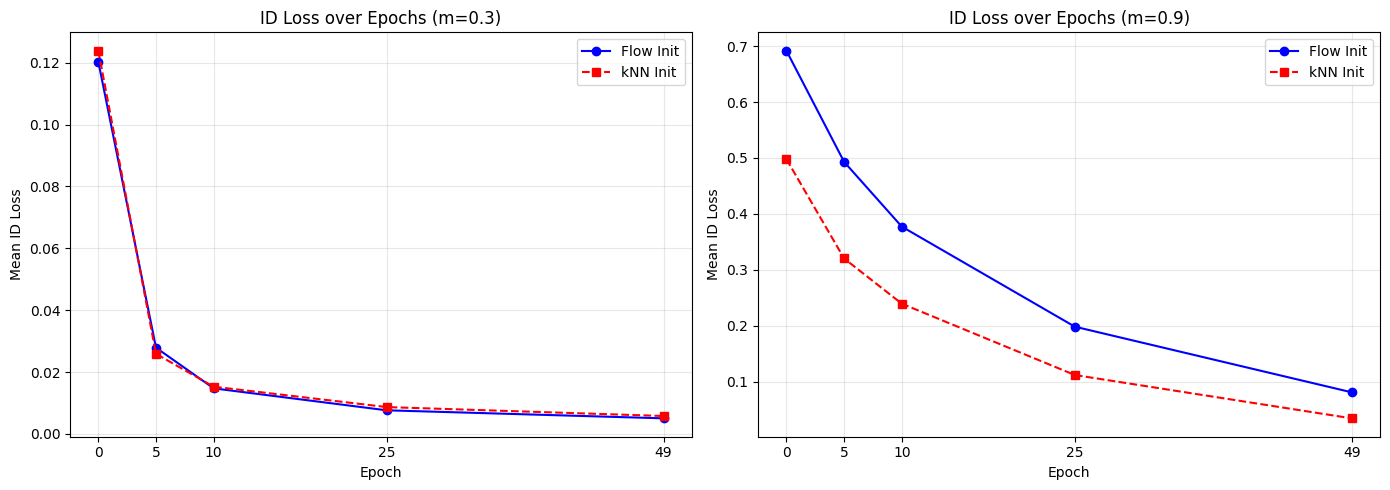

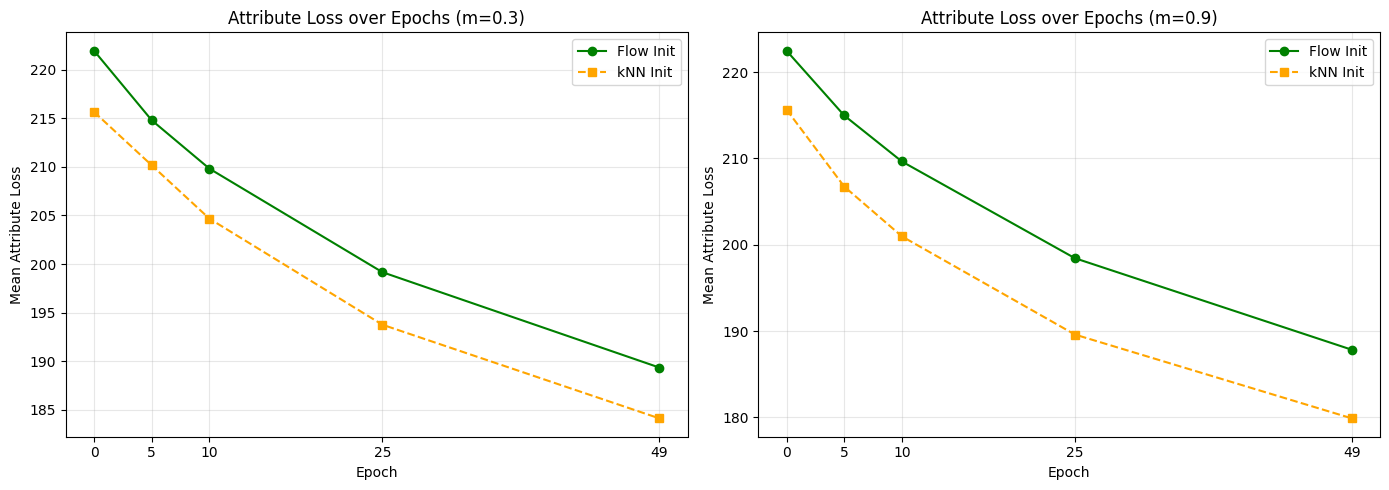

In [6]:
# ==========================================
# PLOT 3: ID Loss vs. Epochs
# ==========================================
fig3, (ax5, ax6) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot A: m = 0.3
if not flow_m03.empty and not knn_m03.empty:
    ax5.plot(flow_m03['epoch'], flow_m03['id_loss'], marker='o', linestyle='-', color='blue', label='Flow Init')
    ax5.plot(knn_m03['epoch'], knn_m03['id_loss'], marker='s', linestyle='--', color='red', label='kNN Init')
ax5.set_title('ID Loss over Epochs (m=0.3)')
ax5.set_xlabel('Epoch')
ax5.set_ylabel('Mean ID Loss')
ax5.set_xticks(flow_m03['epoch'] if not flow_m03.empty else [])
ax5.grid(True, alpha=0.3)
ax5.legend()

# Subplot B: m = 0.9
if not flow_m09.empty and not knn_m09.empty:
    ax6.plot(flow_m09['epoch'], flow_m09['id_loss'], marker='o', linestyle='-', color='blue', label='Flow Init')
    ax6.plot(knn_m09['epoch'], knn_m09['id_loss'], marker='s', linestyle='--', color='red', label='kNN Init')
ax6.set_title('ID Loss over Epochs (m=0.9)')
ax6.set_xlabel('Epoch')
ax6.set_ylabel('Mean ID Loss')
ax6.set_xticks(flow_m09['epoch'] if not flow_m09.empty else [])
ax6.grid(True, alpha=0.3)
ax6.legend()

plt.tight_layout()
plt.show()

# ==========================================
# PLOT 4: Attribute Loss vs. Epochs
# ==========================================
fig4, (ax7, ax8) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot A: m = 0.3
if not flow_m03.empty and not knn_m03.empty:
    ax7.plot(flow_m03['epoch'], flow_m03['att_loss'], marker='o', linestyle='-', color='green', label='Flow Init')
    ax7.plot(knn_m03['epoch'], knn_m03['att_loss'], marker='s', linestyle='--', color='orange', label='kNN Init')
ax7.set_title('Attribute Loss over Epochs (m=0.3)')
ax7.set_xlabel('Epoch')
ax7.set_ylabel('Mean Attribute Loss')
ax7.set_xticks(flow_m03['epoch'] if not flow_m03.empty else [])
ax7.grid(True, alpha=0.3)
ax7.legend()

# Subplot B: m = 0.9
if not flow_m09.empty and not knn_m09.empty:
    ax8.plot(flow_m09['epoch'], flow_m09['att_loss'], marker='o', linestyle='-', color='green', label='Flow Init')
    ax8.plot(knn_m09['epoch'], knn_m09['att_loss'], marker='s', linestyle='--', color='orange', label='kNN Init')
ax8.set_title('Attribute Loss over Epochs (m=0.9)')
ax8.set_xlabel('Epoch')
ax8.set_ylabel('Mean Attribute Loss')
ax8.set_xticks(flow_m09['epoch'] if not flow_m09.empty else [])
ax8.grid(True, alpha=0.3)
ax8.legend()

plt.tight_layout()
plt.show()

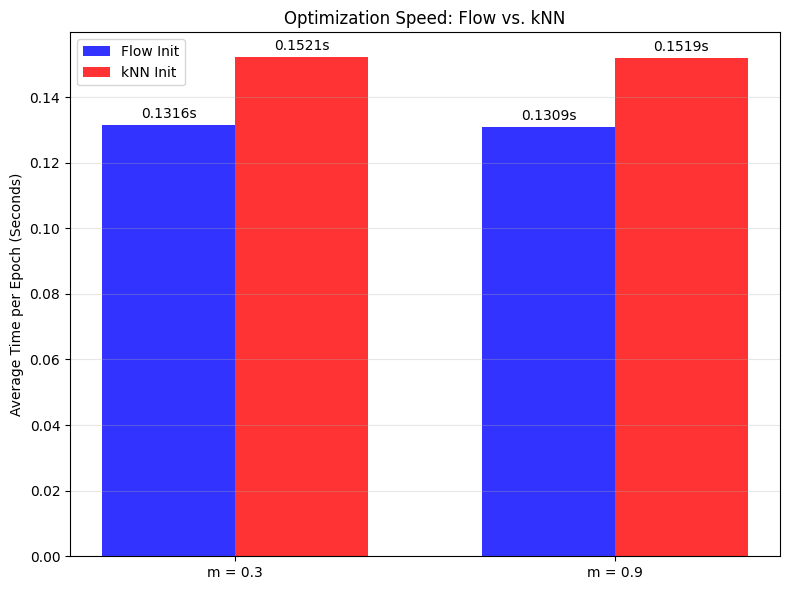

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Calculate the average time per epoch for each configuration
# (Max cumulative wall clock time / 50 epochs)
total_epochs = 50

# Ensure dataframes aren't empty before calculating
time_flow_m03 = flow_m03['wall_clock_time'].max() / total_epochs if not flow_m03.empty else 0
time_knn_m03  = knn_m03['wall_clock_time'].max() / total_epochs if not knn_m03.empty else 0

time_flow_m09 = flow_m09['wall_clock_time'].max() / total_epochs if not flow_m09.empty else 0
time_knn_m09  = knn_m09['wall_clock_time'].max() / total_epochs if not knn_m09.empty else 0

# Setup the plot data
labels = ['m = 0.3', 'm = 0.9']
flow_times = [time_flow_m03, time_flow_m09]
knn_times = [time_knn_m03, time_knn_m09]

# Create the bar plot
x = np.arange(len(labels))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots(figsize=(8, 6))
rects1 = ax.bar(x - width/2, flow_times, width, label='Flow Init', color='blue', alpha=0.8)
rects2 = ax.bar(x + width/2, knn_times, width, label='kNN Init', color='red', alpha=0.8)

# Formatting
ax.set_ylabel('Average Time per Epoch (Seconds)')
ax.set_title('Optimization Speed: Flow vs. kNN')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
ax.grid(axis='y', alpha=0.3)

# Add value labels on top of the bars for exact precision
def autolabel(rects):
    """Attach a text label above each bar, displaying its height."""
    for rect in rects:
        height = rect.get_height()
        if height > 0:  # Only label if data exists
            ax.annotate(f'{height:.4f}s',
                        xy=(rect.get_x() + rect.get_width() / 2, height),
                        xytext=(0, 3),  # 3 points vertical offset
                        textcoords="offset points",
                        ha='center', va='bottom')

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()

=== Summary Statistics Across All Seeds & Images ===
       arcface_cos  arcface_cos_std  id_loss  id_loss_std  att_loss  \
epoch                                                                 
0           0.1262           0.0848   0.1741       0.0842  221.4950   
5           0.2854           0.0484   0.0392       0.0310  213.1073   
10          0.3068           0.0282   0.0217       0.0187  207.7260   
25          0.2979           0.0074   0.0066       0.0037  196.0268   
49          0.3019           0.0070   0.0053       0.0048  185.6323   

       att_loss_std  
epoch                
0           16.2876  
5           18.1557  
10          19.2298  
25          20.4109  
49          20.6241  


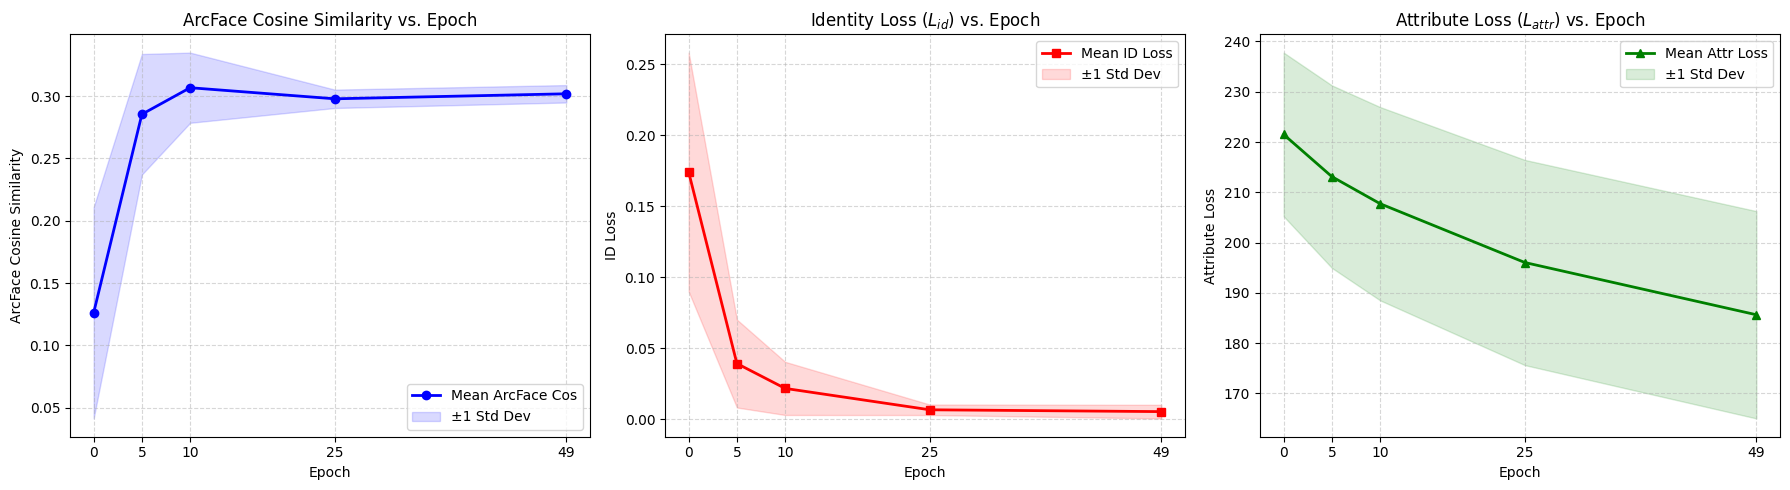

In [15]:
import glob
import matplotlib.pyplot as plt
import pandas as pd


def load_and_process_data(file_pattern="convergence_log_flow_*.csv"):
    """Loads a single combined CSV or concatenates multiple seed CSV files,

    then computes mean and standard deviation per epoch across all samples.
    """
    files = glob.glob(file_pattern)

    df_list = []
    for f in files:
        try:
            temp_df = pd.read_csv(f)
            df_list.append(temp_df)
        except FileNotFoundError:
            continue

    if not df_list:
        raise FileNotFoundError(f"No CSV files found matching: {file_pattern}")

    df = pd.concat(df_list, ignore_index=True)

    # Calculate Mean and Standard Deviation grouped by Epoch across all seeds & images
    mean_stats = df.groupby("epoch")[
        ["arcface_cos", "id_loss", "att_loss", "wall_clock_time"]
    ].mean()
    std_stats = df.groupby("epoch")[
        ["arcface_cos", "id_loss", "att_loss"]
    ].std()

    return mean_stats, std_stats, df


# ==========================================
# 1. Load Data & Compute Summary Statistics
# ==========================================
# Pass your filename or pattern (e.g., 'convergence_log_flow_*.csv' or 'combined_log.csv')
mean_df, std_df, raw_df = load_and_process_data("/home/s142301038-unnikrishnan/tard/FALCO/endterm/logs/m_0.3/convergence_log_flow_*.csv")

print("=== Summary Statistics Across All Seeds & Images ===")
summary_table = mean_df.copy()
summary_table["arcface_cos_std"] = std_df["arcface_cos"]
summary_table["id_loss_std"] = std_df["id_loss"]
summary_table["att_loss_std"] = std_df["att_loss"]

# Display key epochs for report tables
print(
    summary_table[
        [
            "arcface_cos",
            "arcface_cos_std",
            "id_loss",
            "id_loss_std",
            "att_loss",
            "att_loss_std",
        ]
    ].round(4)
)

# ==========================================
# 2. Plotting (Pure Matplotlib)
# ==========================================
epochs = mean_df.index.values

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

# ------------------------------------------
# Plot A: ArcFace Cosine Similarity
# ------------------------------------------
ax1.plot(
    epochs,
    mean_df["arcface_cos"],
    marker="o",
    linestyle="-",
    color="blue",
    linewidth=2,
    label="Mean ArcFace Cos",
)
ax1.fill_between(
    epochs,
    mean_df["arcface_cos"] - std_df["arcface_cos"],
    mean_df["arcface_cos"] + std_df["arcface_cos"],
    color="blue",
    alpha=0.15,
    label="±1 Std Dev",
)
ax1.set_title("ArcFace Cosine Similarity vs. Epoch")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("ArcFace Cosine Similarity")
ax1.set_xticks(epochs)
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()

# ------------------------------------------
# Plot B: ID Loss (L_id)
# ------------------------------------------
ax2.plot(
    epochs,
    mean_df["id_loss"],
    marker="s",
    linestyle="-",
    color="red",
    linewidth=2,
    label="Mean ID Loss",
)
ax2.fill_between(
    epochs,
    mean_df["id_loss"] - std_df["id_loss"],
    mean_df["id_loss"] + std_df["id_loss"],
    color="red",
    alpha=0.15,
    label="±1 Std Dev",
)
ax2.set_title("Identity Loss ($L_{id}$) vs. Epoch")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("ID Loss")
ax2.set_xticks(epochs)
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend()

# ------------------------------------------
# Plot C: Attribute Loss (L_attr)
# ------------------------------------------
ax3.plot(
    epochs,
    mean_df["att_loss"],
    marker="^",
    linestyle="-",
    color="green",
    linewidth=2,
    label="Mean Attr Loss",
)
ax3.fill_between(
    epochs,
    mean_df["att_loss"] - std_df["att_loss"],
    mean_df["att_loss"] + std_df["att_loss"],
    color="green",
    alpha=0.15,
    label="±1 Std Dev",
)
ax3.set_title("Attribute Loss ($L_{attr}$) vs. Epoch")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Attribute Loss")
ax3.set_xticks(epochs)
ax3.grid(True, linestyle="--", alpha=0.5)
ax3.legend()

plt.tight_layout()
plt.show()